<a href="https://colab.research.google.com/github/krishdesai6009/krish-desai/blob/main/23BDS0266.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler

# Plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

2. Load Dataset

In [2]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/econmath.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


3. View Dataset

In [4]:
df.head()
df.tail()
df.shape
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  856 non-null    int64  
 1   age       856 non-null    int64  
 2   work      856 non-null    float64
 3   study     856 non-null    float64
 4   econhs    856 non-null    int64  
 5   colgpa    856 non-null    float64
 6   hsgpa     856 non-null    float64
 7   acteng    814 non-null    float64
 8   actmth    814 non-null    float64
 9   act       814 non-null    float64
 10  mathscr   856 non-null    int64  
 11  male      856 non-null    int64  
 12  calculus  856 non-null    int64  
 13  attexc    856 non-null    int64  
 14  attgood   856 non-null    int64  
 15  fathcoll  856 non-null    int64  
 16  mothcoll  856 non-null    int64  
 17  score     856 non-null    float64
dtypes: float64(8), int64(10)
memory usage: 120.5 KB


4. Basic Statistical Analysis

In [5]:
df.describe()
df.describe(include='all')
df.dtypes
df.nunique()

,0
rownames,856
age,9
work,44
study,52
econhs,2
colgpa,612
hsgpa,531
acteng,23
actmth,23
act,20


5. Check Missing Values

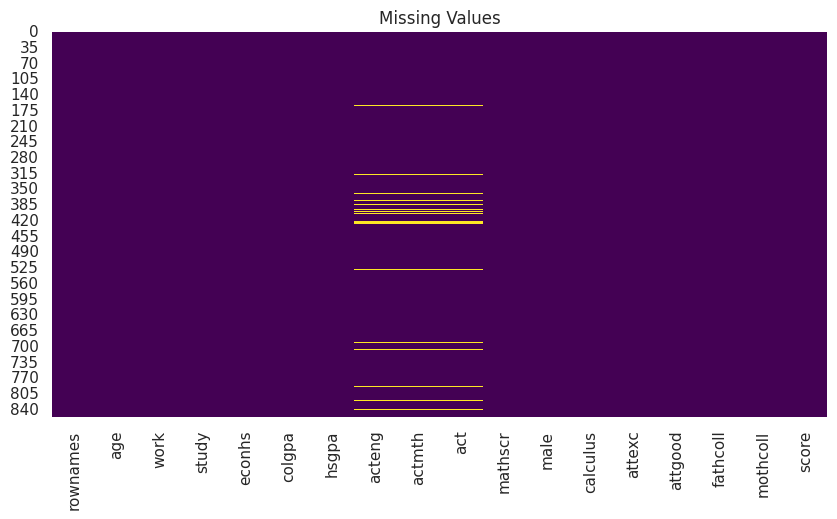

In [6]:
df.isnull().sum()
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),cbar=False,cmap="viridis")
plt.title("Missing Values")
plt.show()

6. Handle Missing Values

In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col].fillna(df[col].median(), inplace=True)

categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)
df.isnull().sum()

/tmp/ipykernel_1710/3738852434.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


,0
rownames,0
age,0
work,0
study,0
econhs,0
colgpa,0
hsgpa,0
acteng,0
actmth,0
act,0


7. Remove Duplicate Records

In [10]:
print("Duplicates :",df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates after removing :",df.duplicated().sum())

Duplicates : 0
Duplicates after removing : 0


8. Data Transformation

In [11]:
#Label Encoding
le = LabelEncoder()

for col in categorical_columns:
    df[col]=le.fit_transform(df[col])

#Feature Scaling
scaler=StandardScaler()

df_scaled=df.copy()

df_scaled[numeric_columns]=scaler.fit_transform(df[numeric_columns])

df_scaled.head()



,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
0,-1.730029,3.837667,0.691135,-0.502317,-0.766894,1.260292,0.036623,0.375134,0.761103,1.190058,1.227916,1.0,0.691673,-0.649559,-1.190831,0.952081,0.768816,0.883321
1,-1.725982,3.837667,-0.935215,1.100280,1.303961,-1.331995,-0.359615,0.104380,-0.870377,0.270939,0.650073,1.0,-1.445771,-0.649559,-1.190831,-1.050330,0.768816,-1.136413
2,-1.721935,1.701749,1.775369,-0.245901,-0.766894,0.503983,-0.106139,-0.437129,0.217277,-0.648179,0.072230,1.0,0.691673,1.539506,-1.190831,-1.050330,0.768816,-0.463666
3,-1.717888,2.769708,2.317485,3.343917,-0.766894,-0.250090,1.848831,2.270414,1.304930,2.415549,1.227916,-1.0,0.691673,-0.649559,0.839750,0.952081,0.768816,0.638414
4,-1.713841,2.769708,1.775369,0.138722,1.303961,1.734616,1.595355,1.458151,2.120670,2.721922,0.072230,1.0,0.691673,-0.649559,0.839750,-1.050330,0.768816,1.739748


9. Univariate Analysis (3 Visualizations)

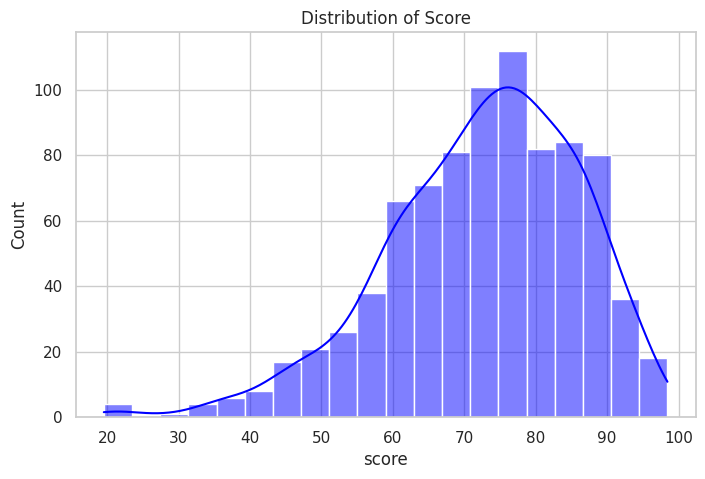

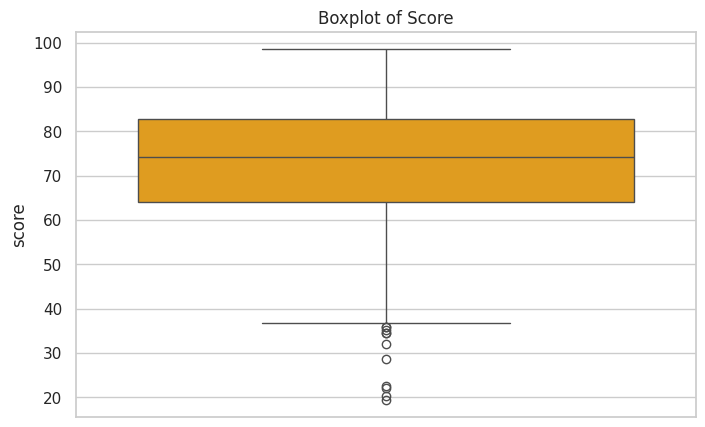

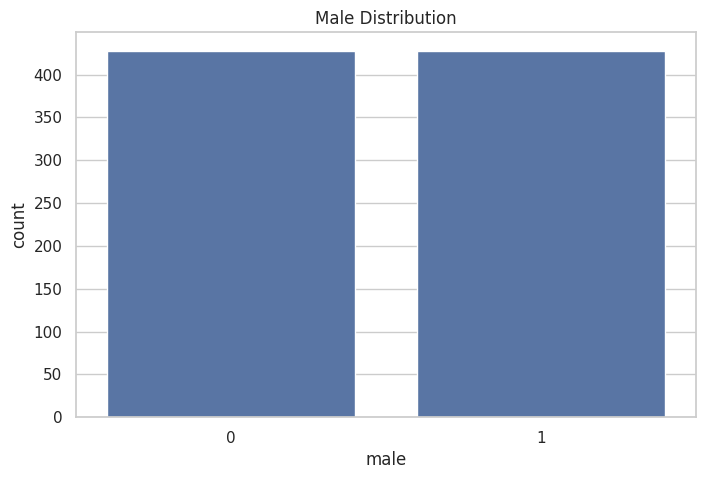

In [12]:
#Histogram
plt.figure(figsize=(8,5))
sns.histplot(df["score"],bins=20,kde=True,color="blue")
plt.title("Distribution of Score")
plt.show()

#Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(y=df["score"],color="orange")
plt.title("Boxplot of Score")
plt.show()

#Countplot
plt.figure(figsize=(8,5))
sns.countplot(x=df["male"])
plt.title("Male Distribution")
plt.show()

10. Bivariate Analysis (3 Visualizations)

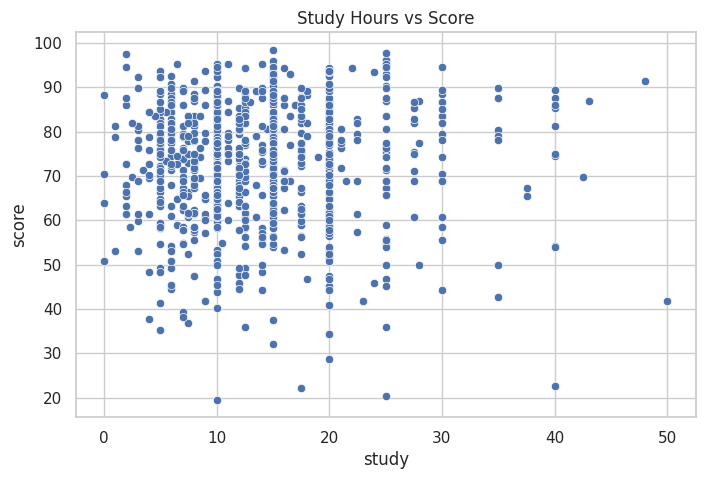

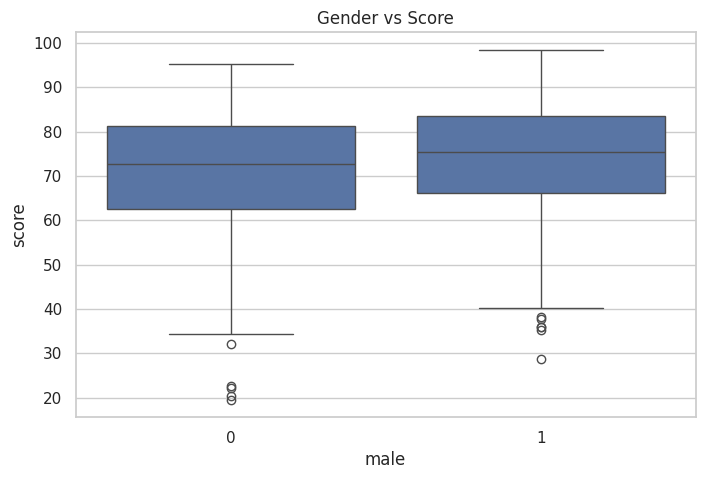

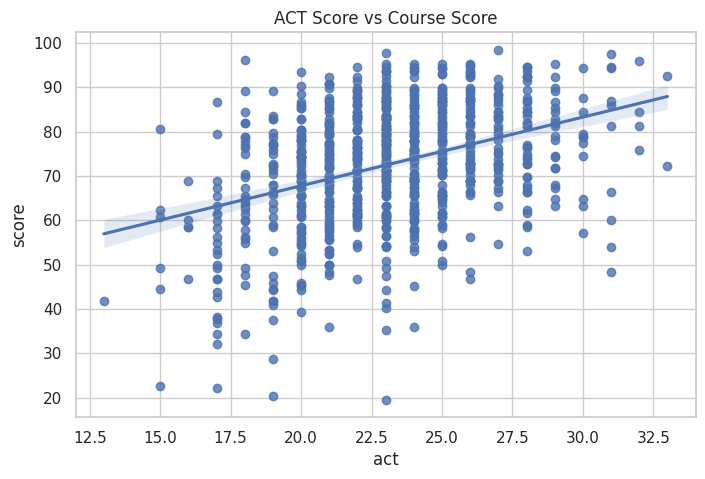

In [13]:
#Scatter plot
plt.figure(figsize=(8,5))
sns.scatterplot(x="study",y="score",data=df)
plt.title("Study Hours vs Score")
plt.show()

#Box plot
plt.figure(figsize=(8,5))
sns.boxplot(x="male",y="score",data=df)
plt.title("Gender vs Score")
plt.show()

#Regression plot
plt.figure(figsize=(8,5))
sns.regplot(x="act",y="score",data=df)
plt.title("ACT Score vs Course Score")
plt.show()

11. Multivariate Analysis (3 Visualizations)

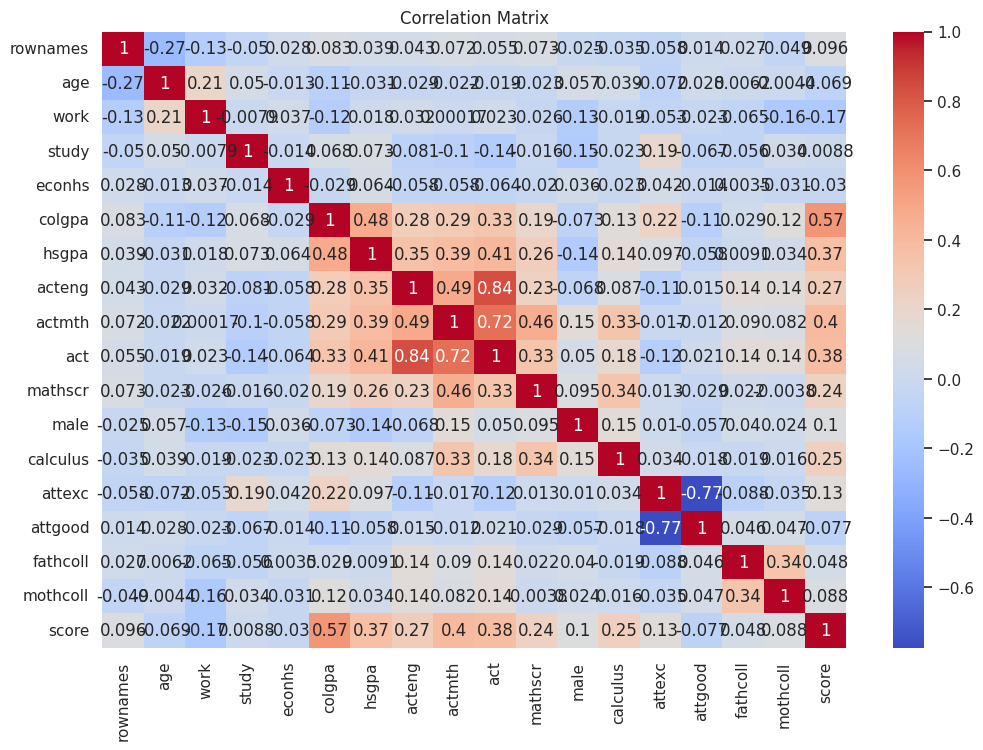

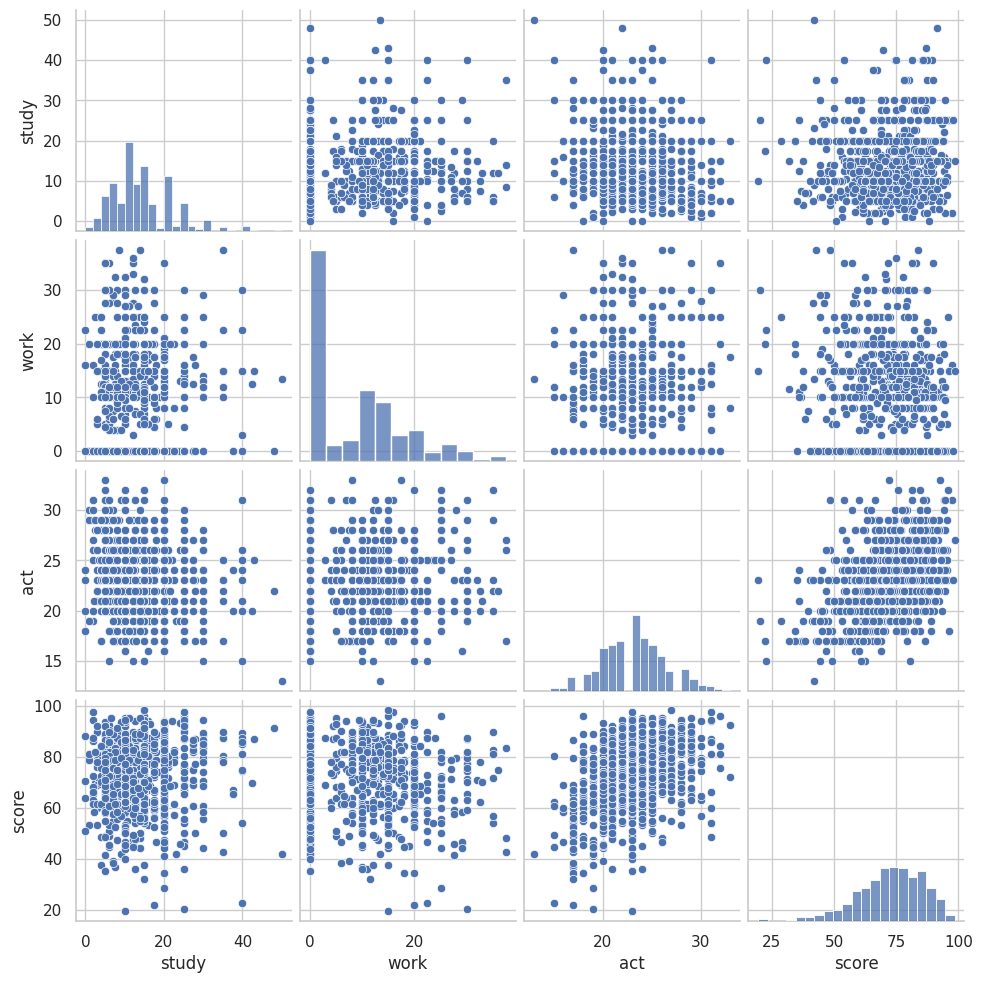

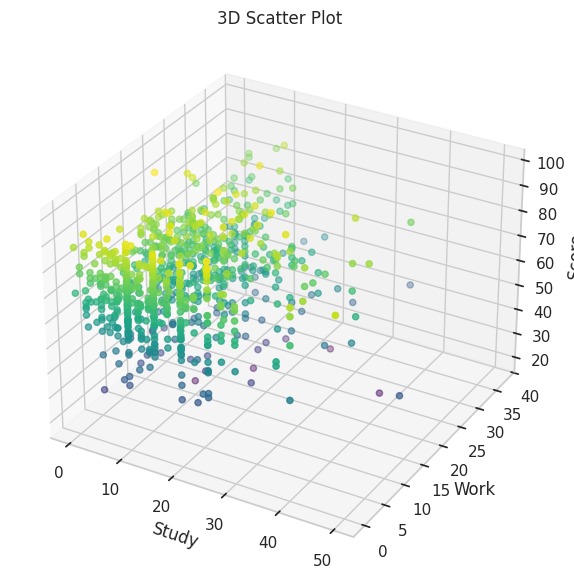

In [14]:
#Correlation Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

#Pair plot
sns.pairplot(df[['study','work','act','score']])
plt.show()

#3D Scatter Plot
from mpl_toolkits.mplot3d import Axes3D

fig=plt.figure(figsize=(10,7))

ax=fig.add_subplot(111,projection='3d')

ax.scatter(df['study'],
           df['work'],
           df['score'],
           c=df['score'],
           cmap='viridis')

ax.set_xlabel("Study")

ax.set_ylabel("Work")

ax.set_zlabel("Score")

plt.title("3D Scatter Plot")
plt.show()

#

12. Outlier Detection

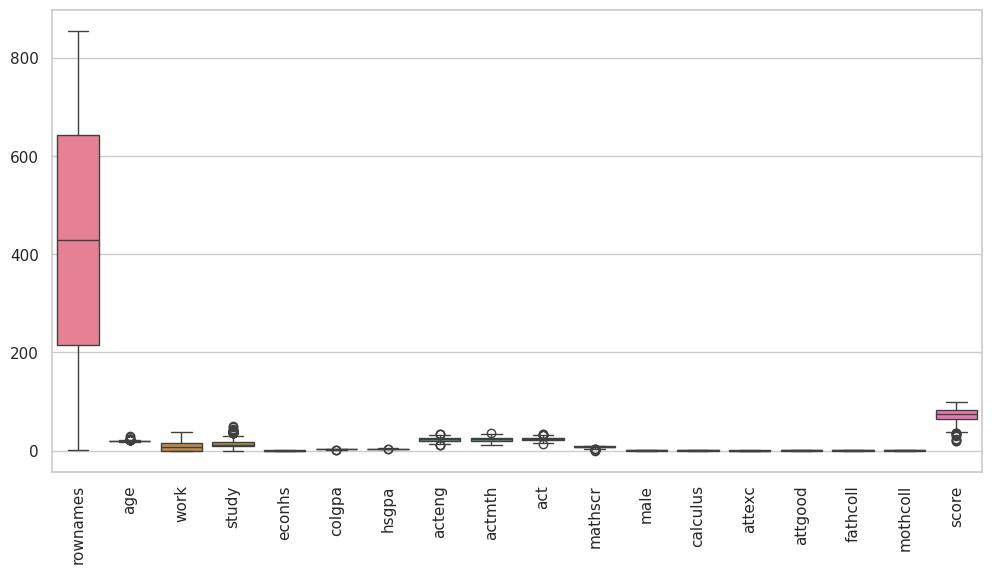

In [15]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df[numeric_columns])

plt.xticks(rotation=90)

plt.show()

13. Correlation with Target

In [16]:
corr=df.corr()

corr["score"].sort_values(ascending=False)

,score
score,1.000000
colgpa,0.573519
actmth,0.395067
act,0.377270
hsgpa,0.367549
acteng,0.268210
calculus,0.251967
mathscr,0.244440
attexc,0.128161
male,0.100331


14. Final Dataset

In [17]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  856 non-null    int64  
 1   age       856 non-null    int64  
 2   work      856 non-null    float64
 3   study     856 non-null    float64
 4   econhs    856 non-null    int64  
 5   colgpa    856 non-null    float64
 6   hsgpa     856 non-null    float64
 7   acteng    856 non-null    float64
 8   actmth    856 non-null    float64
 9   act       856 non-null    float64
 10  mathscr   856 non-null    int64  
 11  male      856 non-null    int64  
 12  calculus  856 non-null    int64  
 13  attexc    856 non-null    int64  
 14  attgood   856 non-null    int64  
 15  fathcoll  856 non-null    int64  
 16  mothcoll  856 non-null    int64  
 17  score     856 non-null    float64
dtypes: float64(8), int64(10)
memory usage: 120.5 KB


15. Conclusion

In [18]:
print("""
EDA Completed Successfully

1. Dataset Loaded
2. Statistical Summary Generated
3. Missing Values Handled
4. Duplicate Records Removed
5. Data Transformed
6. Univariate Analysis Completed
7. Bivariate Analysis Completed
8. Multivariate Analysis Completed
""")


EDA Completed Successfully

1. Dataset Loaded
2. Statistical Summary Generated
3. Missing Values Handled
4. Duplicate Records Removed
5. Data Transformed
6. Univariate Analysis Completed
7. Bivariate Analysis Completed
8. Multivariate Analysis Completed

